In [ ]:
import os
import numpy as np
import pandas as pd

In [ ]:
file_path = os.getcwd() + "/twcs_filtered_labeled_1.csv"
file_path

'/content/twcs_filtered_labeled_1.csv'

In [ ]:
df = pd.read_csv(file_path)
df.head()

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,label
0,2,115712.0,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0,General / Other
1,3,115712.0,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0,General / Other
2,5,115712.0,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0,General / Other
3,8,115712.0,True,Tue Oct 31 21:45:10 +0000 2017,@sprintcare is the worst customer service,"9,6,10",NaN,General / Other
4,12,115713.0,True,Tue Oct 31 22:04:47 +0000 2017,@sprintcare You gonna magically change your co...,"11,13,14",15.0,General / Other


In [ ]:
df.shape

(76404, 8)

In [ ]:
df.isna().sum()

,0
tweet_id,0
author_id,4
inbound,4
created_at,8
text,8
response_tweet_id,17815
in_response_to_tweet_id,25010
label,0


In [ ]:
# drop examples with a null value in the
df = df.dropna(subset=['text'])

In [ ]:
df.isna().sum()

,0
tweet_id,0
author_id,0
inbound,0
created_at,0
text,0
response_tweet_id,17807
in_response_to_tweet_id,25002
label,0


In [ ]:
df["text"].head(10)

,text
0,@sprintcare and how do you propose we do that
1,@sprintcare I have sent several private messag...
2,@sprintcare I did.
3,@sprintcare is the worst customer service
4,@sprintcare You gonna magically change your co...
5,@sprintcare Since I signed up with you....Sinc...
6,@Ask_Spectrum Would you like me to email you a...
7,@Ask_Spectrum I received this from your corpor...
8,@Ask_Spectrum The correct way to do it is via ...
9,@Ask_Spectrum That is INCORRECT information I ...


In [ ]:
df['label'].value_counts()

,count
label,
General / Other,52468
Device & Technical Support,10387
Network & Connectivity,6085
Billing & Payment,3088
Account & Plan Management,2619
Cancellation & Retention,1749


In [ ]:
# Task #5: Remove @mentions from the text feature

df["clean_text"] = df["text"].str.replace(
    r"@\w+",
    "",
    regex=True
)

# Verify removal
print("Rows with @mentions before:",
      df["text"].str.contains(r"@\w+", regex=True, na=False).sum())

print("Rows with @mentions after:",
      df["clean_text"].str.contains(r"@\w+", regex=True, na=False).sum())

Rows with @mentions before: 76396
Rows with @mentions after: 0


In [ ]:
# Task #6A: Remove URLs from the text feature

print("Rows with URLs before:",
      df["clean_text"].str.contains(
          r"https?://\S+", regex=True, na=False
      ).sum())

df["clean_text"] = df["clean_text"].str.replace(
    r"https?://\S+",
    "",
    regex=True
)

# Verify removal
print("Rows with URLs after:",
      df["clean_text"].str.contains(
          r"https?://\S+", regex=True, na=False
      ).sum())

Rows with URLs before: 6272
Rows with URLs after: 0


In [ ]:
# Task #6B: Decode HTML entities (e.g., &amp; to &, &lt; to <)

import html

html_pattern = r"&(?:[A-Za-z]+|#\d+|#x[0-9A-Fa-f]+);"

print("Rows with HTML entities before:",
      df["clean_text"].str.contains(
          html_pattern, regex=True, na=False
      ).sum())

df["clean_text"] = df["clean_text"].apply(
    lambda x: html.unescape(x) if isinstance(x, str) else x
)

# Verify decoding
print("Rows with HTML entities after:",
      df["clean_text"].str.contains(
          html_pattern, regex=True, na=False
      ).sum())

Rows with HTML entities before: 2439
Rows with HTML entities after: 0


In [ ]:
# Display examples where preprocessing changed the original text

changed_rows = df["text"] != df["clean_text"]

df.loc[changed_rows, ["text", "clean_text"]].sample(80)

,text,clean_text
63063,@sprintcare Give up? Lol,Give up? Lol
16482,@Ask_Spectrum I think your speedtest server is...,I think your speedtest server is broke. All o...
37339,@sprintcare everything your telling hem is goi...,everything your telling hem is going in throu...
19693,"@Ask_Spectrum Sorry for the delay, hard to get...","Sorry for the delay, hard to get these tweets..."
58210,@TMobileHelp Y’all some shit,Y’all some shit
...,...,...
42595,@TMobileHelp @115913 It sucks you can't help u...,It sucks you can't help unless I DM you. It ...
43719,@TMobileHelp -cess and wait for 24 hours for a...,-cess and wait for 24 hours for apple to do “...
66104,"@Ask_Spectrum Bangor, Maine 04401. Thank you","Bangor, Maine 04401. Thank you"
67445,"@TMobileHelp stop hitting on me please, i’m no...","stop hitting on me please, i’m not sexually a..."


In [ ]:
# Confirm the cleaned dataset has the original structure

print(df.shape)
print(df.columns.tolist())

print("Remaining @mentions:",
      df["text"].str.contains(r"@\w+", regex=True, na=False).sum())

print("Remaining URLs:",
      df["text"].str.contains(r"https?://\S+", regex=True, na=False).sum())

(76396, 9)
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id', 'label', 'clean_text']
Remaining @mentions: 76396
Remaining URLs: 6272


In [ ]:
# Update the original text feature with the cleaned text and restore the original dataset structure

df["text"] = df["clean_text"]
df.drop(columns=["clean_text"], inplace=True)

print(df.shape)
print(df.columns.tolist())

(76396, 8)
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id', 'label']


In [ ]:
# Task 2: dropping 'General / Other' label from data by setting examples with it to NaN and then dropping NaN values by the label column
df['label'] = np.where(df['label'] == "General / Other", np.nan, df['label'])
df = df.dropna(subset=['label'])

df['label'].value_counts();

In [ ]:
# Task 7: normalizing 'text' feature (turning all characters into lowercase + removing punctuation and special characters)
upper_unicodes = range(65, 91)
lower_unicodes = range(97, 123)

def normalize_text(text: str) -> str:
    result = "";
    for character in text:
        unicode = ord(character)
        if unicode in upper_unicodes or unicode in lower_unicodes or unicode == 32:
            result += character
    return result.lower()

df['text'] = df['text'].apply(normalize_text)
df['text']

,text
8,the correct way to do it is via an ocs accoun...
15,what else can i provide they refuse to help m...
16,how i have my phone number and email thats it...
17,dont know router is downstairs but its just t...
18,just randomly boots me offline there it goes ...
...,...
76396,my internet is dead in carmel in is there an ...
76398,vudu credit is not working
76400,internet out for about an hour now pced the r...
76401,wifi is tripping this happens every month ge...


In [ ]:
df['text'].sample(20)

,text
10022,actually it appears the internet is back now ...
14084,service outage in rego park queens
68268,exactly when are you guys going to resolve wh...
40734,mbps down and mbps up is there an outage in t...
51411,my internet is still down what is the issue
69540,yes we are unable to test because no devices ...
13404,it didnt break when i asked about screen prot...
29599,the roku app keeps crashing when i go to on d...
72205,now our internet is out too come on
36269,any outages in falls church virginia my mothe...


In [ ]:
df.shape

(23928, 8)

In [ ]:
df.isna().sum()

,0
tweet_id,0
author_id,0
inbound,0
created_at,0
text,0
response_tweet_id,3503
in_response_to_tweet_id,11671
label,0


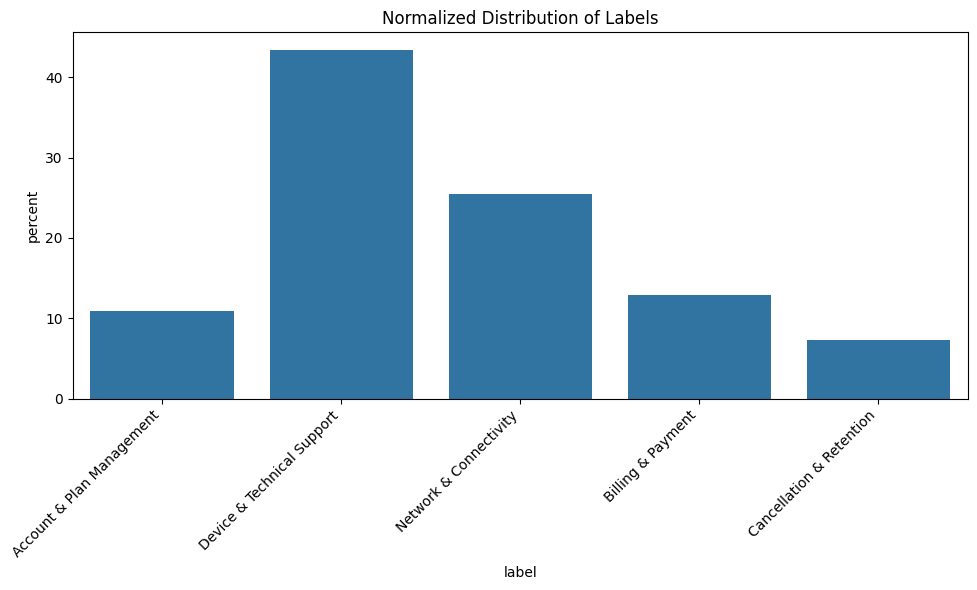

In [ ]:
# create a plot that displays the normalized distribution of labels in the dataset

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='label', stat='percent')
plt.xticks(rotation=45, ha='right')
plt.title('Normalized Distribution of Labels')
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv(os.getcwd() + "/cleaned_twcs_filtered_labeled_1.csv", index=False)

In [ ]:
# dropping all columns besides the tweets and labels
list_of_columns = list(df.columns)
list_of_columns.remove("text")
list_of_columns.remove("label")

df = df.drop(columns=list_of_columns)
df.head()

,text,label
8,the correct way to do it is via an ocs accoun...,Account & Plan Management
15,what else can i provide they refuse to help m...,Account & Plan Management
16,how i have my phone number and email thats it...,Device & Technical Support
17,dont know router is downstairs but its just t...,Device & Technical Support
18,just randomly boots me offline there it goes ...,Network & Connectivity


In [ ]:
#creating a weight dictionary for data training to ensure all labels get equal attention
labels = list(df['label'].unique())
count = df['label'].value_counts()

label_counts = []
for i in labels:
  label_counts.append(count[i])

def weight(N, C, samples):
    label_weight = N/(C*samples)
    return label_weight

weights_dict = {}

N = len(df)
C = len(labels)

for label in labels:
  samples = count[label]
  label_weight = weight(N, C, samples)
  weights_dict[label] = label_weight

weights_dict

{'Account & Plan Management': np.float64(1.827262313860252),
 'Device & Technical Support': np.float64(0.46072975835178587),
 'Network & Connectivity': np.float64(0.7864585045193098),
 'Billing & Payment': np.float64(1.5497409326424871),
 'Cancellation & Retention': np.float64(2.7361921097770154)}

In [ ]:
# prepare data for model training: spliting data into 80% training and 20% validation
from sklearn.model_selection import train_test_split

X = df['text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [ ]:
# prepare data for model training: TF-IDF vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)